<a href="https://colab.research.google.com/github/dohyunii/computer-vision-study/blob/main/ELLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import torch.optim.lr_scheduler as lr_scheduler
from torchvision.transforms import v2
from torchvision.io import decode_image

import matplotlib.pyplot as plt

##Dataset

In [ ]:
train_transform = v2.Compose([
    v2.RandomResizedCrop(size=(32, 32), antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
test_transform = v2.Compose([
    v2.RandomResizedCrop(size=(32, 32), antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)

## **ResNet**

In [ ]:
class Conv1(nn.Sequential):
  def __init__(self, n_in=3, n_out=64, kernel_size=7, stride=2):
    super().__init__(
        nn.Conv2d(n_in, n_out, kernel_size=kernel_size, stride=stride, padding=(kernel_size - 1) // 2, bias=False),
        nn.BatchNorm2d(n_out),
        nn.ReLU(inplace=True)
        )

In [ ]:
class ResidualUnit(nn.Module):
  def __init__(self, n_in, n_out, stride=1, bottleneck=True):
    super().__init__()
    self.relu = nn.ReLU()

    # Residual Path
    if bottleneck:
      n_resized = n_out // 4
      self.residual_path = nn.Sequential(
          nn.Conv2d(n_in, n_resized, kernel_size=1, stride=stride, padding=0, bias=False),
          nn.BatchNorm2d(n_resized),
          nn.ReLU(inplace=True),

          nn.Conv2d(n_resized, n_resized, kernel_size=3, stride=1, padding=1, bias=False),
          nn.BatchNorm2d(n_resized),
          nn.ReLU(inplace=True),

          nn.Conv2d(n_resized, n_out, kernel_size=1, stride=1, padding=0, bias=False),
          nn.BatchNorm2d(n_out)
          )
    else:
      self.residual_path = nn.Sequential(
          nn.Conv2d(n_in, n_out, kernel_size=3, stride=stride, padding=1, bias=False),
          nn.BatchNorm2d(n_out),
          nn.ReLU(inplace=True),

          nn.Conv2d(n_out, n_out, kernel_size=3, stride=1, padding=1, bias=False),
          nn.BatchNorm2d(n_out)
      )

    # Shortcut Path
    if stride != 1 or n_in != n_out:
      self.shortcut = nn.Sequential(
          nn.Conv2d(n_in, n_out, kernel_size=1, stride=stride, padding=0, bias=False), # !bias <- batch normalization
          nn.BatchNorm2d(n_out)
      )
    else:
      self.shortcut = nn.Identity()

  def forward(self, x):
    return self.relu(self.shortcut(x) + self.residual_path(x))

In [ ]:
class ConvX(nn.Sequential):
  def __init__(self, n_in, n_out, layer_num, stride=2,bottleneck=True):
    super().__init__()

    self.append(residual_unit(n_in=n_in, n_out=n_out, stride=stride, bottleneck=bottleneck))
    for i in range(layer_num - 1):
      self.append(residual_unit(n_in=n_out, n_out=n_out, stride=1, bottleneck=bottleneck))

In [ ]:
class FC(nn.Module):
  def __init__(self, n_in, num_classes=10):
    super().__init__()
    self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
    self.fc = nn.Linear(n_in, num_classes)

  def forward(self, x):
    x = self.avgpool(x)
    x = torch.flatten(x, 1)
    x = self.fc(x)
    return x

In [ ]:
class ResNet(nn.Sequential):
  def __init__(self, conv_num: list, conv1_kernel=7, conv1_stride=2, init_n=64, num_classes=1000, max_pool=True, bottleneck=True):
    super().__init__(Conv1(n_in=3, n_out=init_n, kernel_size=conv1_kernel, stride=conv1_stride))
    if max_pool:
      self.append(nn.MaxPool2d(kernel_size=3, stride=2, padding=1))
    n_in = n_out = init_n
    for idx, layer_num in enumerate(conv_num):
      stride = 1 if idx == 0 else 2
      self.append(ConvX(n_in, n_out, layer_num=layer_num, stride=stride, bottleneck=bottleneck))
      n_in = n_out
      n_out <<= 1
    self.append(FC(n_in, num_classes))


## **PreActResNet**

In [ ]:
class PreActResidualUnit(nn.Module):
  def __init__(self, in_channels: int, planes: int, stride: int = 1, bottleneck: bool = True):
    super().__init__()
    expansion = 4 if bottleneck else 1
    out_channels = planes * expansion
    self.bn1 = nn.BatchNorm2d(in_channels)
    self.relu = nn.ReLU(inplace=True)

    self.shortcut = (
        nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False)
        if stride != 1 or in_channels != out_channels
        else None
    )

    if bottleneck:
      self.conv1 = nn.Conv2d(in_channels, planes, 1, stride=stride, bias=False)
      self.bn2 = nn.BatchNorm2d(planes)
      self.conv2 = nn.Conv2d(planes, planes, 3, padding=1, bias=False)
      self.bn3 = nn.BatchNorm2d(planes)
      self.conv3 = nn.Conv2d(planes, out_channels, 1, bias=False)
    else:
      self.conv1 = nn.Conv2d(in_channels, planes, 3, stride=stride, padding=1, bias=False)
      self.bn2 = nn.BatchNorm2d(planes)
      self.conv2 = nn.Conv2d(planes, out_channels, 3, padding=1, bias=False)
      self.conv3 = None

def forward(self, x):
    preact = self.relu(self.bn1(x))

    identity = (x if self.shortcut is None else self.shortcut(preact))

    out = self.conv1(preact)
    out = self.conv2(self.relu(self.bn2(out)))

    if self.conv3 is not None:
      out = self.conv3(self.relu(self.bn3(out)))

    return identity + out

In [ ]:
class PreActResNet(nn.Module):
  def __init__(self, layers, stage_planes=(64, 128, 256, 512), stem_channels=64, stem_kernel=7, stem_stride=2, max_pool=True, bottleneck=True, num_classes=1000):
    super().__init__()

    self.bottleneck = bottleneck
    self.in_channels = stem_channels

    self.stem = nn.Sequential(
        nn.Conv2d(3, stem_channels, kernel_size=stem_kernel, stride=stem_stride, padding=(stem_kernel - 1) // 2, bias=False),
        nn.MaxPool2d(3, stride=2, padding=1) if max_pool else nn.Identity()
    )
    self.stages = nn.ModuleList([
        self._make_stage(planes, n_blocks, stride=1 if idx == 0 else 2) for idx, (planes, n_blocks) in enumerate(zip(stage_planes, layers))
    ])

    self.bn = nn.BatchNorm2d(self.in_channels)
    self.relu = nn.ReLU(inplace=True)

    self.avgpool = nn.AdaptiveAvgPool2d(1)
    self.fc = nn.Linear(self.in_channels, num_classes)

def _make_stage(self, planes, n_blocks, stride):
    expansion = 4 if self.bottleneck else 1
    out_channels = planes * expansion

    self.in_channels = out_channels

    blocks = [PreActResidualUnit(self.in_channels, planes, stride=stride, bottleneck=self.bottleneck)]
    for _ in range(n_blocks - 1):
      blocks.append(PreActResidualUnit(out_channels, planes, stride=1, bottleneck=self.bottleneck))

    return nn.Sequential(*blocks)


def forward(self, x):
    x = self.stem(x)

    for stage in self.stages:
        x = stage(x)

    x = self.relu(self.bn(x))
    x = self.avgpool(x)
    x = torch.flatten(x, 1)

    return self.fc(x)

## **DenseNet**

In [ ]:
class DenseNet(nn.Sequential):
  def __init__(self, dense_block = 3, bottleneck=False, compression=False):



## Hyperparameters

In [ ]:
# ResNet
# Bottleneck
# model = ResNet([3, 4, 6, 3], num_classes=10, max_pool=False, bottleneck=True)
# Paper Version for CIFAR
# model = ResNet([3, 3, 3], conv1_kernel=3, conv1_stride=1, init_n=16, num_classes=10, max_pool=False, bottleneck=False)

# PreActResNet
# Bottleneck
# model = PreActResNet([3, 4, 6, 3], num_classes=10, max_pool=False, bottleneck=True)
# Paper Version for CIFAR
# model = PreActResNet([3, 3, 3], conv1_kernel=3, conv1_stride=1, init_n=16, num_classes=10, max_pool=False, bottleneck=False)

# DenseNet

_lr = 0.1
_weight_decay = 0.0001
_batch_size = 128
_epochs = 100
_momentum = 0.9

##Data Loader

In [ ]:
train_loader = DataLoader(dataset=train_dataset, batch_size=_batch_size, shuffle=True, num_workers=8, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=_batch_size, shuffle=False, num_workers=8, pin_memory=True, persistent_workers=True)

## Training and Testing

###Training

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

train_losses = []

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=_lr,
    momentum=_momentum,
    weight_decay=_weight_decay
)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer,
    milestones=[40, 70],
    gamma=0.1
)
num_epochs = _epochs

for epoch in range(num_epochs):
  model.train()

  running_loss = 0.0
  correct = 0
  total = 0

  for inputs, labels in train_loader:
    inputs = inputs.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()
    logits = model(inputs)
    loss = loss_function(logits, labels)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * inputs.size(0)
    _, predicted = logits.max(dim=1)
    total += labels.size(0)
    correct += predicted.eq(labels).sum().item()

  scheduler.step()
  epoch_loss = running_loss / total
  epoch_accuracy = 100.0 * correct / total

  train_losses.append(epoch_loss)

  print(
      f"Epoch [{epoch + 1:3d}/{num_epochs}] "
      f"| Train Loss: {epoch_loss:.4f} "
      f"| Train Acc: {epoch_accuracy:.2f}% "
  )

Epoch [  1/100] | Train Loss: 1.8201 | Train Acc: 31.65% 
Epoch [  2/100] | Train Loss: 1.5198 | Train Acc: 44.78% 
Epoch [  3/100] | Train Loss: 1.3345 | Train Acc: 51.86% 
Epoch [  4/100] | Train Loss: 1.2285 | Train Acc: 56.13% 
Epoch [  5/100] | Train Loss: 1.1497 | Train Acc: 58.93% 
Epoch [  6/100] | Train Loss: 1.0825 | Train Acc: 61.51% 
Epoch [  7/100] | Train Loss: 1.0357 | Train Acc: 63.49% 
Epoch [  8/100] | Train Loss: 0.9953 | Train Acc: 64.81% 
Epoch [  9/100] | Train Loss: 0.9634 | Train Acc: 65.86% 
Epoch [ 10/100] | Train Loss: 0.9366 | Train Acc: 66.87% 
Epoch [ 11/100] | Train Loss: 0.9110 | Train Acc: 68.13% 
Epoch [ 12/100] | Train Loss: 0.8937 | Train Acc: 68.76% 
Epoch [ 13/100] | Train Loss: 0.8843 | Train Acc: 69.02% 
Epoch [ 14/100] | Train Loss: 0.8653 | Train Acc: 69.73% 
Epoch [ 15/100] | Train Loss: 0.8514 | Train Acc: 70.29% 
Epoch [ 16/100] | Train Loss: 0.8442 | Train Acc: 70.29% 
Epoch [ 17/100] | Train Loss: 0.8267 | Train Acc: 71.18% 
Epoch [ 18/100

###Training Graph

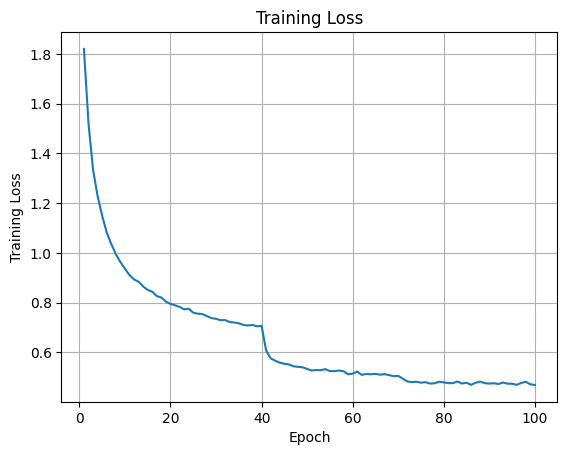

In [ ]:
plt.plot(range(1, num_epochs + 1), train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")
plt.grid()
plt.show()

###Testing

In [ ]:
model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        logits = model(inputs)
        loss = loss_function(logits, labels)

        test_loss += loss.item() * inputs.size(0)

        _, predicted = logits.max(dim=1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

test_loss = test_loss / total
test_accuracy = 100.0 * correct / total

print(
    f"Test Loss: {test_loss:.4f} "
    f"| Test Acc: {test_accuracy:.2f}%"
)

Test Loss: 0.5451 | Test Acc: 81.61%
